In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Gold_Dec_26.csv')
df.head()

,Price,Close,High,Low,Open,Volume
0,Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
1,Date,NaN,NaN,NaN,NaN,NaN
2,2000-08-30,273.8999938964844,273.8999938964844,273.8999938964844,273.8999938964844,0
3,2000-08-31,278.29998779296875,278.29998779296875,274.79998779296875,274.79998779296875,0
4,2000-09-01,277.0,277.0,277.0,277.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6563 entries, 0 to 6562
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Price   6563 non-null   str  
 1   Close   6562 non-null   str  
 2   High    6562 non-null   str  
 3   Low     6562 non-null   str  
 4   Open    6562 non-null   str  
 5   Volume  6562 non-null   str  
dtypes: str(6)
memory usage: 307.8 KB


Rows 0 and 1 (Ticker GC=F… and Date NaN…). Because of them, every column is read as text, not numbers. I should Load it by skipping the two first Rows 0 ans 1, I reload the file with `skiprows=[1, 2]` to skip these two lines

In [4]:
df = pd.read_csv('Gold_Dec_26.csv', skiprows=[1, 2])
df = df.rename(columns={'Price': 'Date'})
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')
df.head()

,Close,High,Low,Open,Volume
Date,,,,,
2000-08-30,273.899994,273.899994,273.899994,273.899994,0
2000-08-31,278.299988,278.299988,274.799988,274.799988,0
2000-09-01,277.000000,277.000000,277.000000,277.000000,0
2000-09-05,275.799988,275.799988,275.799988,275.799988,2
2000-09-06,274.200012,274.200012,274.200012,274.200012,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6561 entries, 2000-08-30 to 2026-10-21
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   6561 non-null   float64
 1   High    6561 non-null   float64
 2   Low     6561 non-null   float64
 3   Open    6561 non-null   float64
 4   Volume  6561 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 307.5 KB


The data types are now correct, I need to print the first and last date to see the period of data. and also I need to check if the dates are in order because the Times Series depend on the times sequence. 

In [6]:
end_Date = df.index.max().date()
start_Date = df.index.min().date()
print(f'First Date : {start_Date}\nLast Date : {end_Date}')

First Date : 2000-08-30
Last Date : 2026-10-21


In [7]:
df.index.is_monotonic_increasing

True

After checking the chronogical order of dates, I should use `df.describe()` to see the minimum and maximum and the average of each column 

In [8]:
df.describe()

,Close,High,Low,Open,Volume
count,6561.000000,6561.000000,6561.000000,6561.000000,6561.000000
mean,1354.986831,1364.280994,1345.273266,1355.010456,51317.783112
std,919.961699,930.775494,908.476161,919.848664,92461.844497
min,255.100006,256.100006,255.000000,255.000000,0.000000
25%,660.299988,662.000000,658.900024,660.400024,29.000000
50%,1260.800049,1267.400024,1254.699951,1260.300049,199.000000
75%,1728.599976,1739.800049,1718.500000,1730.599976,87026.000000
max,5318.399902,5586.200195,5272.899902,5415.700195,570055.000000


There are no missing values because all 6561 rows have values in every column. From roughly **(min)** 255 USD in 2000 to a high close of **(max)** 5318.40. Which mean the gold increase in these period given (2000 - 2026), The standard deviation of the prices is very big (around 920). This is mainly because the price kept going up over the years. The data starts in 2000, but the assessment asks for the last ten years, so I will remove the older rows later.


# **Missing values, duplicates**

In [9]:
missing_values = df.isnull().sum()
missing_values

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

There is no missing values, let's check if There is any duplicates dates

In [10]:
duplicates_values = df.duplicated().sum()
print(duplicates_values)

41


In [11]:
duplicates_dates = df.index.duplicated().sum()
duplicates_dates

np.int64(0)

At first I used `df.duplicated()`, but that checks if whole rows have the same values, not if the same date appears twice. It found 41 rows, but these were different days that just had the same prices, so they are real days and I should not delete them.

In [12]:
check_neg_values = df[['Close', 'High', 'Low', 'Open']] <= 0
check_neg_values.any(axis = 1).sum()

np.int64(0)

In [13]:
(df['High'] < df['Low']).sum()

np.int64(1)

In [14]:
((df['Open'] > df['High']) | (df['Open'] < df['Low'])).sum()

np.int64(56)

In [15]:
((df['Close'] > df['High']) | (df['Close'] < df['Low'])).sum()

np.int64(430)

In [16]:
((df['Volume'] == 0).sum())

np.int64(418)

### Last 10 years

In [17]:
# currentDate = pd.Timestamp.now()
# lastTenYear = pd.DateOffset(years = 10)

# # currentDate
# ten_years_ago = (currentDate - lastTenYear).date()
# print(ten_years_ago)
start_date = '2016-10-21'
end_date = '2026-10-20'



In [18]:
df_10_years = df.loc[start_date: end_date]
df_10_years

,Close,High,Low,Open,Volume
Date,,,,,
2016-10-21,1265.900024,1265.900024,1265.900024,1265.900024,224
2016-10-24,1262.000000,1269.199951,1261.800049,1269.199951,42
2016-10-25,1271.900024,1274.099976,1264.099976,1264.099976,61
2016-10-26,1264.800049,1274.000000,1264.800049,1274.000000,279
2016-10-27,1267.900024,1269.400024,1267.900024,1269.400024,338
...,...,...,...,...,...
2026-10-14,4107.899902,4193.500000,4095.000000,4184.200195,191279
2026-10-15,4170.100098,4197.700195,4120.899902,4128.299805,159510
2026-10-16,4181.100098,4220.399902,4167.500000,4192.100098,137939


In [19]:
print(len(df_10_years))

2513


In [20]:
df_10_years.describe()

,Close,High,Low,Open,Volume
count,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000
mean,2100.841743,2117.194230,2083.653999,2100.651532,127860.603263
std,975.148469,990.480386,958.777356,974.970352,110035.380647
min,1127.800049,1132.800049,1123.900024,1126.900024,0.000000
25%,1335.400024,1340.500000,1328.500000,1335.000000,330.000000
50%,1815.900024,1827.300049,1804.900024,1816.699951,147947.000000
75%,2327.000000,2346.100098,2310.899902,2329.899902,205084.000000
max,5318.399902,5586.200195,5272.899902,5415.700195,570055.000000


In [21]:
df.describe()

,Close,High,Low,Open,Volume
count,6561.000000,6561.000000,6561.000000,6561.000000,6561.000000
mean,1354.986831,1364.280994,1345.273266,1355.010456,51317.783112
std,919.961699,930.775494,908.476161,919.848664,92461.844497
min,255.100006,256.100006,255.000000,255.000000,0.000000
25%,660.299988,662.000000,658.900024,660.400024,29.000000
50%,1260.800049,1267.400024,1254.699951,1260.300049,199.000000
75%,1728.599976,1739.800049,1718.500000,1730.599976,87026.000000
max,5318.399902,5586.200195,5272.899902,5415.700195,570055.000000


### Compare `df` & `df_10_years`:
> - Gold prices are much higher in this period: the average close is about 2,100 USD compared with about 1,355 USD for the full data, and the lowest close is about 1,128 USD instead of 255 USD.
> - The maximum values did not change (highest close 5,318.40 and highest High 5,586.20), so the record prices happened in the last ten years.

`df_10_years.describe()` showed that 25% of day in the last ten years have a fewer about 330, while the median (50%) is about 148000, which is a big difference.

In [22]:
(df_10_years['High'] < df_10_years['Low']).sum()

np.int64(0)

Let's if the full data changed compar with the data of the last 10 year.

In [23]:
# Remaining checks on the ten-year data
open_outside = ((df_10_years['Open'] > df_10_years['High']) | (df_10_years['Open'] < df_10_years['Low'])).sum()
close_outside = ((df_10_years['Close'] > df_10_years['High']) | (df_10_years['Close'] < df_10_years['Low'])).sum()
zero_volume = (df_10_years['Volume'] == 0).sum()

print('Open outside High-Low range:', open_outside)
print('Close outside High-Low range:', close_outside)
print('Days with zero volume:', zero_volume)

Open outside High-Low range: 0
Close outside High-Low range: 0
Days with zero volume: 36


In the last ten years, the Open and Close are always between the High and the Low, and High is never lower than Low. So all the price problems I found earlier were only in the old years and were removed by the 10 year.

In [24]:

low_volume = df_10_years['Volume'] < 1000
print('Days with volume below 1,000:', low_volume.sum(), 'out of', len(df_10_years))

low_volume.groupby(df_10_years.index.year).sum()

Days with volume below 1,000: 810 out of 2513


Date
2016     41
2017    223
2018    228
2019    224
2020     86
2021      0
2022      0
2023      1
2024      0
2025      5
2026      2
Name: Volume, dtype: int64

> From 2016 to early 2020, almost every day has a tiny volume, and from 2021 onwards almost none do
>  Volume isn’t consistent across the ten years, so we won’t use it as a clustering feature. Otherwise the clusters would mostly separate “before 2020” from “after 2020” instead of different market conditions.

After the data cleaned, I want to name my own data to **gold** and using `copy` to make new data indepent from `df_10_years`

In [25]:
gold = df_10_years.copy()

In [26]:
gold.shape

(2513, 5)

In [27]:
gold.columns 

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')

In [28]:
gold.index.date.min()

datetime.date(2016, 10, 21)

In [29]:
gold.index.date.max()

datetime.date(2026, 10, 20)

# The Golden Rule

As the course recommend :
```
> Logging: In the case where the compound rate in the trend is not due to a price index (i.e., the series is not measured in a currency), logging can helpto linearizea series with an exponential trend (recall that log(exp(x)) = x). It does not remove an eventual trend whatsoever, unlike deflation.

> We use Close, because gold futures have no Adjusted Close.
```



In [30]:
# Daily log return: relative change in the closing price from the previous day
gold['Log_Return'] = np.log(gold['Close'] / gold['Close'].shift(1))
gold[['Close', 'Log_Return']].head()

,Close,Log_Return
Date,,
2016-10-21,1265.900024,NaN
2016-10-24,1262.000000,-0.003086
2016-10-25,1271.900024,0.007814
2016-10-26,1264.800049,-0.005598
2016-10-27,1267.900024,0.002448


As we can see **NaN** in the first row, because the first day has no previous day to compare with
> I calculate the daily price range as a share of the Close price. It shows how much the price moved during the day, which the return does not show. Dividing by Close makes the range comparable across the whole period.

In [31]:
gold['Daily_Range'] = (gold['High'] - gold['Low']) / gold['Close']
gold[['High', 'Low', 'Close', 'Daily_Range']].head()

,High,Low,Close,Daily_Range
Date,,,,
2016-10-21,1265.900024,1265.900024,1265.900024,0.000000
2016-10-24,1269.199951,1261.800049,1262.000000,0.005864
2016-10-25,1274.099976,1264.099976,1271.900024,0.007862
2016-10-26,1274.000000,1264.800049,1264.800049,0.007274
2016-10-27,1269.400024,1267.900024,1267.900024,0.001183


In [32]:
gold

,Close,High,Low,Open,Volume,Log_Return,Daily_Range
Date,,,,,,,
2016-10-21,1265.900024,1265.900024,1265.900024,1265.900024,224,NaN,0.000000
2016-10-24,1262.000000,1269.199951,1261.800049,1269.199951,42,-0.003086,0.005864
2016-10-25,1271.900024,1274.099976,1264.099976,1264.099976,61,0.007814,0.007862
2016-10-26,1264.800049,1274.000000,1264.800049,1274.000000,279,-0.005598,0.007274
2016-10-27,1267.900024,1269.400024,1267.900024,1269.400024,338,0.002448,0.001183
...,...,...,...,...,...,...,...
2026-10-14,4107.899902,4193.500000,4095.000000,4184.200195,191279,-0.016753,0.023978
2026-10-15,4170.100098,4197.700195,4120.899902,4128.299805,159510,0.015028,0.018417
2026-10-16,4181.100098,4220.399902,4167.500000,4192.100098,137939,0.002634,0.012652


> The first day has a range of 0 (High = Low), which looks like the low-volume days. I check the number of zero-range days and the typical (median) range per year, to see if the daily range was also recorded differently before 2020.

# Is the daily range reliable?
 > The moving average model is the simplest approach to time series modelling. This model simply states that the next observation is the mean of all past observations. It is a simple model and it represents a good starting point.

In [33]:

range_by_year = gold.groupby(gold.index.year)['Daily_Range'].agg(
    zero_range_days=lambda s: (s == 0).sum(),
    median_range='median')
range_by_year

,zero_range_days,median_range
Date,,
2016,2,0.009185
2017,11,0.006798
2018,35,0.005011
2019,28,0.005585
2020,2,0.014365
2021,0,0.012286
2022,0,0.013881
2023,0,0.011267
2024,0,0.013069


> While the most zero_range days most before 2020, Low = high which mean high and low were recorded diffently, So I wont use the the Daily_Range or Volume for clustering.

In [34]:
# gold[['Log_Return', 'Volatility_20d']]


In [35]:

gold['Volatility_20d'] = gold['Log_Return'].rolling(window=20).std()
gold[['Log_Return', 'Volatility_20d']].iloc[18:24]  #the first value (18 and 19, still NaN);

,Log_Return,Volatility_20d
Date,,
2016-11-17,-0.005656,NaN
2016-11-18,-0.006598,NaN
2016-11-21,0.000910,0.010810
2016-11-22,0.001157,0.010835
2016-11-23,-0.018250,0.011147
2016-11-25,-0.009209,0.011214


### Why do I use `std()` while the course used the mean() and var() ?
> The course uses mean() for the level and var() for the spread.
> `std` is just the square root of `var`, the same idea as the course’s `var()`. I picked std because it’s in the same units as the returns: 0.01 means “about 1% a day”, which is easy to read. Variance would be 0.0001,

As in Tutorial 5(a) (Machine Learning Course **ARMA Time Series Model
Week 5** ), I plot the data to see how it behaves over time. The top chart shows the Close price and the bottom chart shows the 20-day volatility, so I can see when gold was calm and when it was moving a lot.

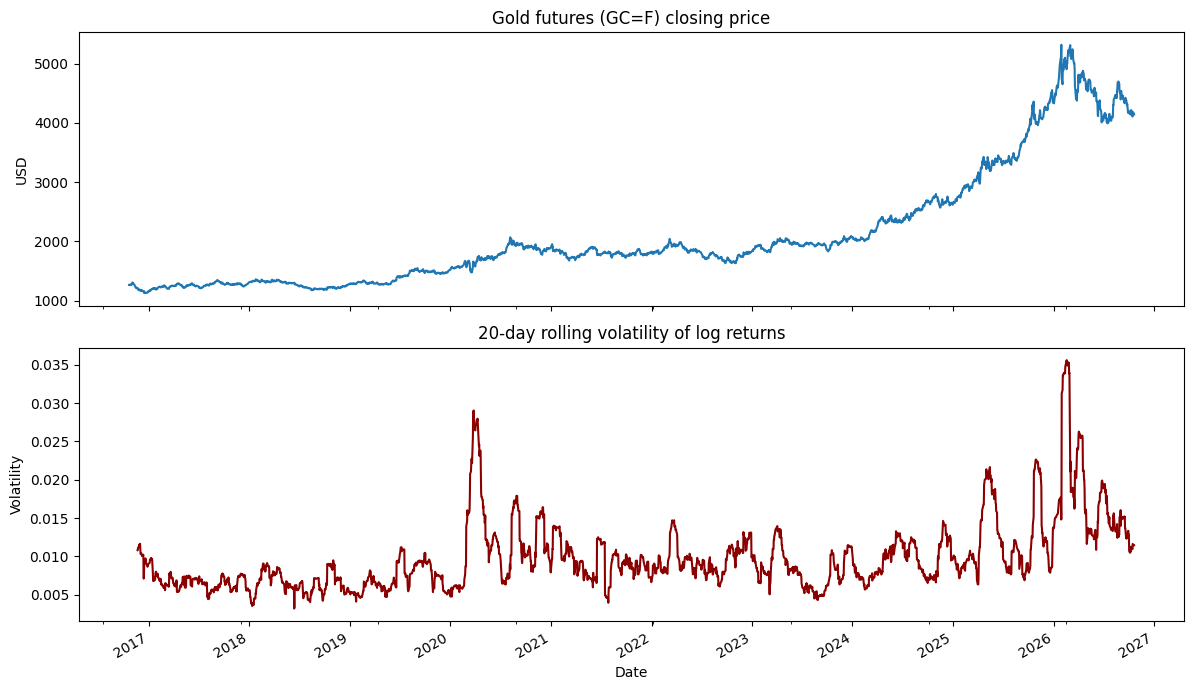

In [36]:
# Plot the Close price and the 20-day volatility one above the other
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

gold['Close'].plot(ax=ax[0], title='Gold futures (GC=F) closing price')
ax[0].set_ylabel('USD')

gold['Volatility_20d'].plot(ax=ax[1], color='darkred', title='20-day rolling volatility of log returns')
ax[1].set_ylabel('Volatility')

plt.tight_layout()
plt.show()

In [37]:
# 20-day return: total log change in the Close price over the last 20 trading days
gold['Return_20d'] = np.log(gold['Close'] / gold['Close'].shift(20))
gold[['Close', 'Return_20d']].iloc[18:24]

,Close,Return_20d
Date,,
2016-11-17,1216.500000,NaN
2016-11-18,1208.500000,NaN
2016-11-21,1209.599976,-0.045494
2016-11-22,1211.000000,-0.041251
2016-11-23,1189.099976,-0.067315
2016-11-25,1178.199951,-0.070926


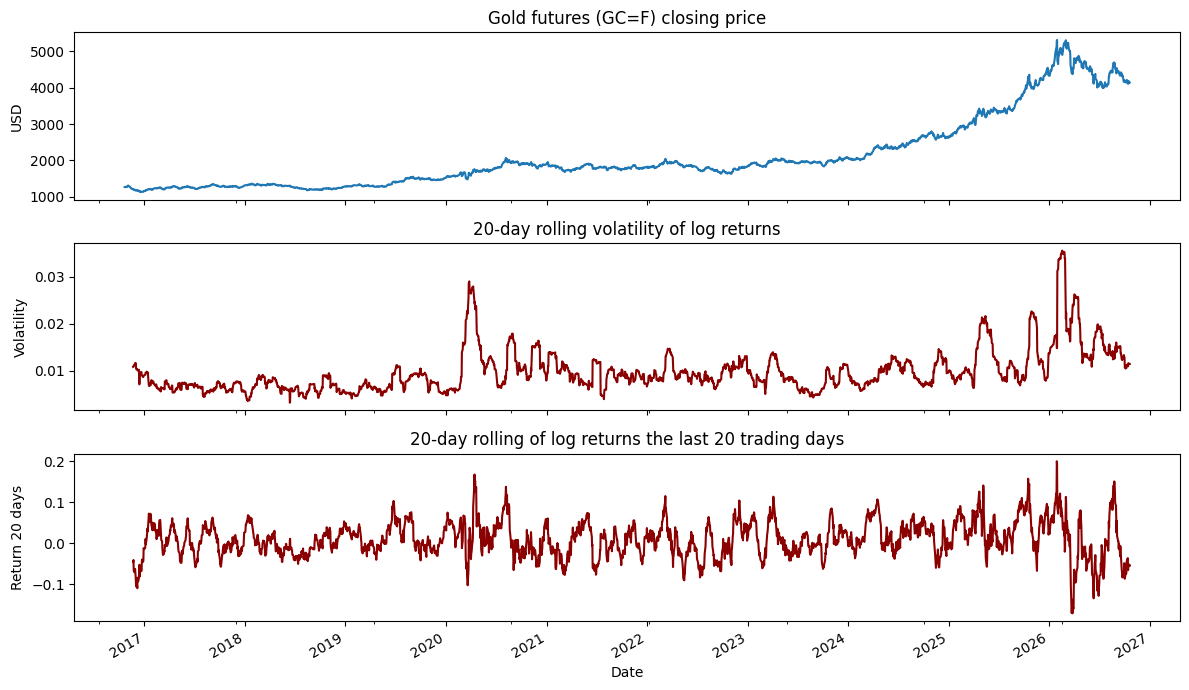

In [38]:
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

gold['Close'].plot(ax=ax[0], title='Gold futures (GC=F) closing price')
ax[0].set_ylabel('USD')

gold['Volatility_20d'].plot(ax=ax[1], color='darkred', title='20-day rolling volatility of log returns')
ax[1].set_ylabel('Volatility')

gold['Return_20d'].plot(ax=ax[2], color='darkred', title='20-day rolling of log returns the last 20 trading days')
ax[2].set_ylabel('Return 20 days')

plt.tight_layout()
plt.show()

calculate the 20 day return, which is the change in the Close price over the last 20 trading days. Volatility shows how much gold moves, but not in which direction, so this feature shows whether gold was rising or falling over the last month.

> I summarise which columns came from Yahoo Finance and which I created myself, and how many columns the dataset now has. I also look at the summary statistics of the new features, because they are on different scales and this will matter for clustering.

In [39]:

original_columns = ['Close', 'High', 'Low', 'Open', 'Volume']
derived_columns = ['Log_Return', 'Daily_Range', 'Volatility_20d', 'Return_20d']

print('Original columns:', original_columns)
print('Derived columns :', derived_columns)




Original columns: ['Close', 'High', 'Low', 'Open', 'Volume']
Derived columns : ['Log_Return', 'Daily_Range', 'Volatility_20d', 'Return_20d']


In [40]:
gold.shape # total of columns now is nine 

(2513, 9)

In [41]:
gold[derived_columns].describe()

,Log_Return,Daily_Range,Volatility_20d,Return_20d
count,2512.000000,2513.000000,2493.000000,2493.000000
mean,0.000472,0.013515,0.009766,0.009624
std,0.010732,0.010219,0.004589,0.043224
min,-0.114060,0.000000,0.003188,-0.171339
25%,-0.004400,0.007636,0.006869,-0.017366
50%,0.000680,0.011790,0.008624,0.006864
75%,0.005867,0.017202,0.011214,0.036774
max,0.058926,0.164338,0.035613,0.199682


In [42]:
gold[derived_columns].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2513 entries, 2016-10-21 to 2026-10-20
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Log_Return      2512 non-null   float64
 1   Daily_Range     2513 non-null   float64
 2   Volatility_20d  2493 non-null   float64
 3   Return_20d      2493 non-null   float64
dtypes: float64(4)
memory usage: 98.2 KB


In [43]:
gold[derived_columns].isnull().sum()

Log_Return         1
Daily_Range        0
Volatility_20d    20
Return_20d        20
dtype: int64

### Summary :
> The dataset now has 9 columns (5 from Yahoo and 4 that I created) plus the Date. The 20 day features have 20 missing values at the start. The features are on very different scales, so I will need to scale them before clustering.

# Exploratory data analysis (EDA)

In [44]:
# pip install statsmodels

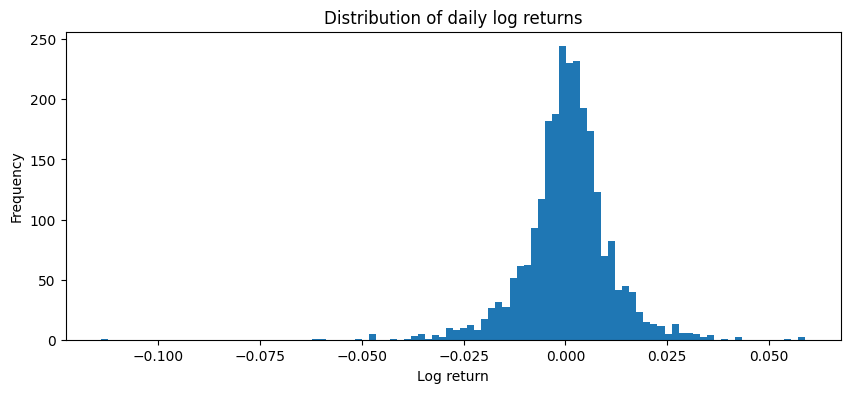

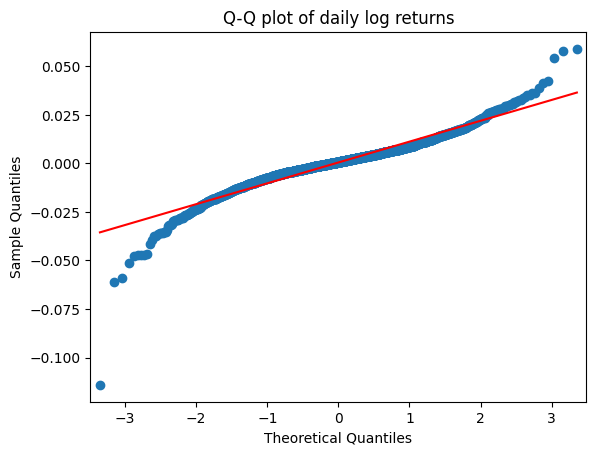

In [45]:
import statsmodels.api as sm

# Distribution of daily log returns
returns = gold['Log_Return'].dropna()

returns.plot(kind='hist', bins=100, figsize=(10, 4), title='Distribution of daily log returns')
plt.xlabel('Log return')
plt.show()

# Q-Q plot, as in Tutorial 6(a): points far from the red line at the ends mean heavy tails
sm.qqplot(returns, line='s')
plt.title('Q-Q plot of daily log returns')
plt.show()

I look at the distribution of the daily log returns with a histogram, and I use a Q-Q plot (as in Tutorial 6(a)) to check if the returns follow a normal distribution. If the points move away from the red line at the ends, it means extreme days happen more often than normal.

## Describe any trends, seasonality, or anomalies observed

> I list the 10 days with the biggest daily price moves (up or down) to find unusual observations. I also show the daily range and volume on those days. I do not remove these days, because they are real market moves, but they can affect the clustering and the forecasting.

In [46]:
gold['Log_Return']

Date
2016-10-21         NaN
2016-10-24   -0.003086
2016-10-25    0.007814
2016-10-26   -0.005598
2016-10-27    0.002448
                ...   
2026-10-14   -0.016753
2026-10-15    0.015028
2026-10-16    0.002634
2026-10-19   -0.005035
2026-10-20   -0.004216
Name: Log_Return, Length: 2513, dtype: float64

In [47]:
gold['Log_Return'].abs() # because there are negative numbers 

Date
2016-10-21         NaN
2016-10-24    0.003086
2016-10-25    0.007814
2016-10-26    0.005598
2016-10-27    0.002448
                ...   
2026-10-14    0.016753
2026-10-15    0.015028
2026-10-16    0.002634
2026-10-19    0.005035
2026-10-20    0.004216
Name: Log_Return, Length: 2513, dtype: float64

In [48]:
gold['Log_Return'].abs().nlargest(10)

Date
2026-01-30    0.114060
2026-03-19    0.061165
2025-10-21    0.059130
2026-02-03    0.058926
2020-03-24    0.057775
2020-03-23    0.054422
2020-11-09    0.051140
2021-06-17    0.047641
2020-03-13    0.047416
2020-02-28    0.047386
Name: Log_Return, dtype: float64

In [49]:
biggest_days = gold['Log_Return'].abs().nlargest(10).index
gold.loc[biggest_days, ['Close', 'Log_Return', 'Daily_Range', 'Volume']]

,Close,Log_Return,Daily_Range,Volume
Date,,,,
2026-01-30,4745.100098,-0.114060,0.164338,508003
2026-03-19,4605.700195,-0.061165,0.078967,303828
2025-10-21,4109.100098,-0.059130,0.073155,535325
2026-02-03,4935.000000,0.058926,0.066444,260114
2020-03-24,1660.199951,0.057775,0.055897,442
2020-03-23,1567.000000,0.054422,0.049011,51
2020-11-09,1854.400024,-0.051140,0.063686,496088
2021-06-17,1774.800049,-0.047641,0.032961,385888
2020-03-13,1515.699951,-0.047416,0.050142,89


### Relationships between the clustering features

Check the correlation between my three clustering features. If two features were very strongly correlated, they would give the same information twice in the clustering. A correlation close to 0 means the features measure different things.

In [50]:
cluster_features = ['Log_Return', 'Volatility_20d', 'Return_20d']
gold[cluster_features].corr().round(2)

,Log_Return,Volatility_20d,Return_20d
Log_Return,1.00,-0.01,0.20
Volatility_20d,-0.01,1.00,0.01
Return_20d,0.20,0.01,1.00


In [51]:
heatmapGold = gold[['Log_Return', 'Volatility_20d', 'Return_20d']]
# heatmapGold

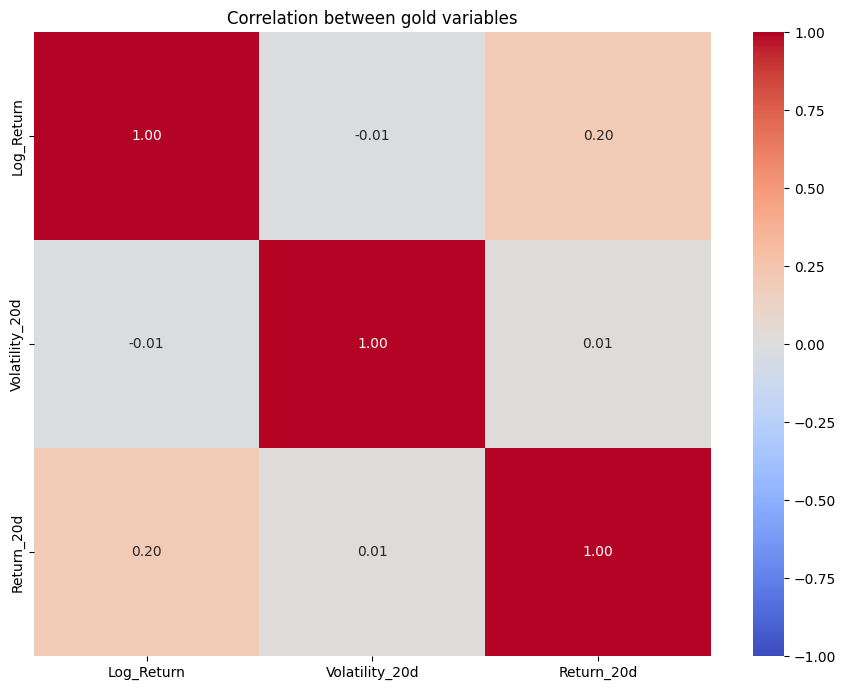

In [52]:
import seaborn as sns

plt.figure(figsize=(9, 7))
sns.heatmap(heatmapGold.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between gold variables')
plt.tight_layout()
plt.show()

# Prepare the features for clustering

Clustering Algorithm can't deal with missing value while we have NaN in `Log_return` so I have to drop them (20 missing values). And also we have to scale our data as we know the Clustring algorithm calcul the Euclidean distance `K-Means`

### StandardScaler

In [53]:
from sklearn.preprocessing import StandardScaler

# Keep only the rows where all three clustering features have values
cluster_data = gold[cluster_features].dropna()
print('Rows used for clustering:' , cluster_data.shape[0])

Rows used for clustering: 2493


In [54]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_data)

X_scaled

array([[ 0.0387476 ,  0.22750362, -1.27540776],
       [ 0.0617723 ,  0.23291829, -1.17724078],
       [-1.74745029,  0.30102096, -1.78035322],
       ...,
       [ 0.19952486,  0.38426452, -1.53410182],
       [-0.51549408,  0.36529176, -1.43520968],
       [-0.43907034,  0.36599764, -1.49313394]], shape=(2493, 3))

In [55]:
print('Means after scaling:', X_scaled.mean(axis=0).round(2))
print('Std after scaling  :', X_scaled.std(axis=0).round(2))

Means after scaling: [-0.  0. -0.]
Std after scaling  : [1. 1. 1.]


### K-Means

> The Elbow method is used to determine the optimal number of clusters in k-means clustering.

> The Elbow method plots the value of the cost function produced by different values of k.

> As you know, if k increases, the average change will decrease, and the instances will be closer to their respective centroids.

> The improvements in average change will reduce as k increases. The value of k at which improvement in change declines the most is called the Elbow, at which we should stop dividing the data into further clusters.

> K-Means needs the number of clusters (k) to be chosen first. I use the Elbow method from Lecture 1 and Tutorial 1: I run K-Means for k = 1 to 10 and record the SSE (the total squared distance of the days from their cluster centre). The best k is around the “elbow”, where adding more clusters does not reduce the SSE much anymore.

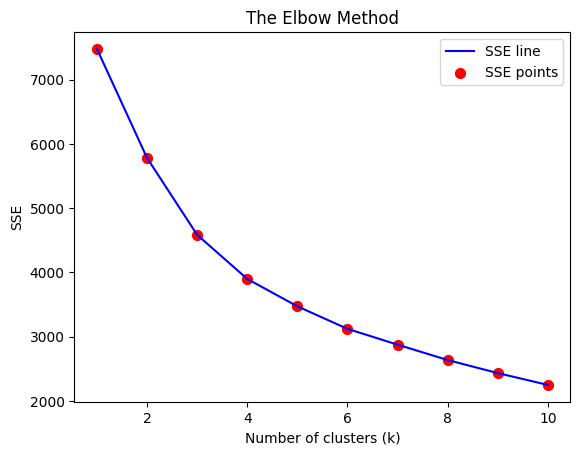

In [56]:

from sklearn.cluster import KMeans
sse = []   # Declare an array for the storage of values for Sum of Squares (SSE) Errors

# Set the loop from the minimum and maximum values
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 42)  # Initialise an object kmeans by calling 
                                                                                     # an object KMeans()
    kmeans.fit(X_scaled)                                                                    # Training the model by calling fit() method
    sse.append(kmeans.inertia_)                                                      # Store kmeans.inertia_ in the array sse

# Plotting the results onto a line graph with points in a different color
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')

plt.title('The Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('SSE')  # sum of squares errors
plt.legend()
plt.show()

### silhouette score and Davies–Bouldin index for each k

> Because the elbow is not clear, I also calculate the silhouette score and the Davies–Bouldin index for k = 2 to 10. A higher silhouette and a lower Davies–Bouldin index mean the clusters are more compact and better separated.

In [57]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [58]:

for k in range(2, 11):          # Silhouette and Davies-Bouldin for k = 2 to 10
    kmeans = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=38)
    labels = kmeans.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)
    print(f'k = {k}:  silhouette = {sil:.3f}   Davies-Bouldin = {dbi:.3f}')

k = 2:  silhouette = 0.255   Davies-Bouldin = 1.506
k = 3:  silhouette = 0.270   Davies-Bouldin = 1.250
k = 4:  silhouette = 0.272   Davies-Bouldin = 1.189
k = 5:  silhouette = 0.241   Davies-Bouldin = 1.210
k = 6:  silhouette = 0.262   Davies-Bouldin = 1.168
k = 7:  silhouette = 0.241   Davies-Bouldin = 1.142
k = 8:  silhouette = 0.219   Davies-Bouldin = 1.161
k = 9:  silhouette = 0.248   Davies-Bouldin = 1.089
k = 10:  silhouette = 0.250   Davies-Bouldin = 1.069


The silhouette score is highest at k = 4 (0.272), very close to k = 3 (0.270), and the Davies–Bouldin index is also better at k = 4 than at k = 3. The Davies–Bouldin index keeps falling for larger k, but this happens because the clusters get smaller, so I do not choose a large k. Combined with the elbow, k = 3 or k = 4 are the best options. The silhouette values are low (about 0.27), which means the clusters are not very clearly separated.

### compare k = 3 and k = 4 by what the clusters mean

> The scores for k = 3 and k = 4 are very close, so I compare both solutions by looking at the size of each cluster and the average values of the features in each cluster. I use the original (unscaled) values so I can describe each cluster in real terms, for example calm or volatile days.

In [59]:
# Compare k = 3 and k = 4: size and average feature values of each cluster
for k in (3, 4):
    kmeans = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    profile = cluster_data.groupby(labels).mean().round(4)
    profile['Days'] = pd.Series(labels).value_counts().sort_index().values
    print(f'\nK-Means with k = {k}')
    display(profile)


K-Means with k = 3


,Log_Return,Volatility_20d,Return_20d,Days
0,0.0054,0.0090,0.0443,1004
1,-0.0028,0.0086,-0.0162,1306
2,-0.0026,0.0221,0.0033,183



K-Means with k = 4


,Log_Return,Volatility_20d,Return_20d,Days
0,0.0048,0.0088,0.0473,887
1,-0.0181,0.0132,-0.0095,259
2,0.0104,0.0225,0.0193,142
3,0.0001,0.0082,-0.0152,1205


### Fit the final K-Means model (k = 3)

> I fit the final K-Means model with k = 3 and save the cluster number of each day as a new column, so I can visualise the clusters and compare them with the second algorithm.

In [60]:
kmeans_final = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=42)
cluster_data['KMeans_Cluster'] = kmeans_final.fit_predict(X_scaled)

cluster_data['KMeans_Cluster'].value_counts().sort_index()

KMeans_Cluster
0    1004
1    1306
2     183
Name: count, dtype: int64

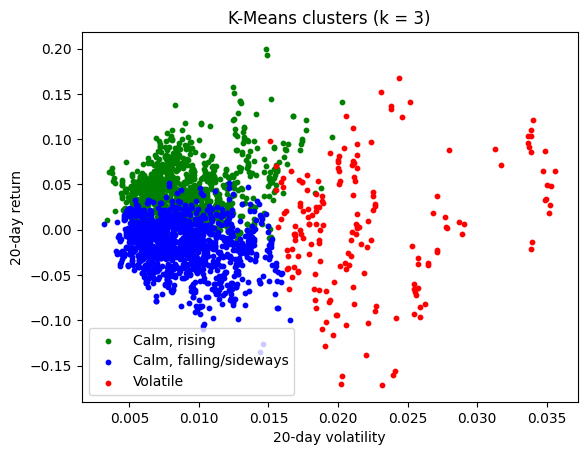

In [61]:
# Scatter plot of the K-Means clusters, as in Tutorial 1
x = cluster_data[['Volatility_20d', 'Return_20d']].values
y_kmeans = cluster_data['KMeans_Cluster'].values

plt.scatter(x[y_kmeans == 0, 0], x[y_kmeans == 0, 1], s = 10, c = 'green', label = 'Calm, rising')
plt.scatter(x[y_kmeans == 1, 0], x[y_kmeans == 1, 1], s = 10, c = 'blue', label = 'Calm, falling/sideways')
plt.scatter(x[y_kmeans == 2, 0], x[y_kmeans == 2, 1], s = 10, c = 'red', label = 'Volatile')

plt.xlabel('20-day volatility')
plt.ylabel('20-day return')
plt.title('K-Means clusters (k = 3)')
plt.legend()
plt.show()

> I plot the days coloured by their K-Means cluster, using the 20-day volatility and the 20-day return, to see how well the three clusters are separated.

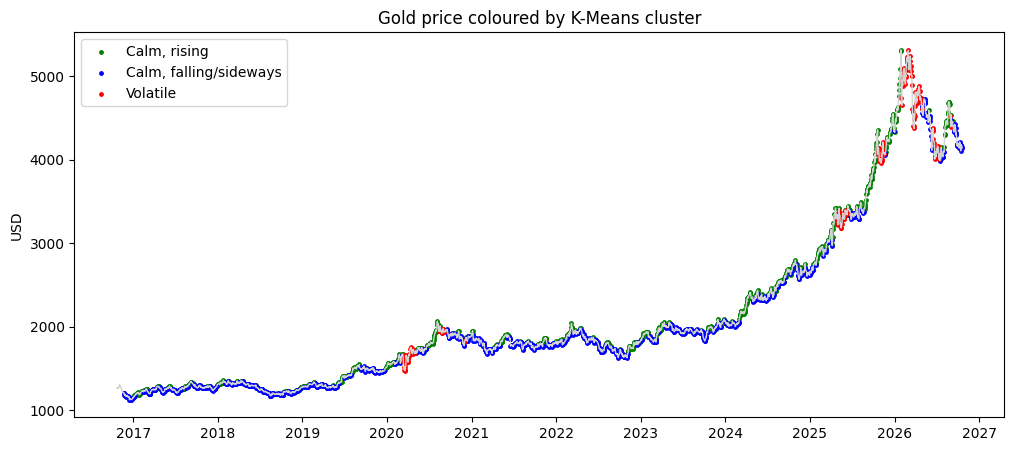

In [62]:

names = {0: 'Calm, rising', 1: 'Calm, falling/sideways', 2: 'Volatile'}
colours = {0: 'green', 1: 'blue', 2: 'red'}

# Gold closing price coloured by K-Means cluster
plt.figure(figsize=(12, 5))
plt.plot(gold.index, gold['Close'], color='lightgrey', linewidth=1)
for cluster, name in names.items():
    days = cluster_data[cluster_data['KMeans_Cluster'] == cluster]
    plt.scatter(days.index, gold.loc[days.index, 'Close'], s=6, color=colours[cluster], label=name)

plt.title('Gold price coloured by K-Means cluster')
plt.ylabel('USD')
plt.legend()
plt.show()


In [63]:
# Share of days in each K-Means cluster per year (%)
(pd.crosstab(cluster_data.index.year, cluster_data['KMeans_Cluster'], normalize='index') * 100).round(1)

KMeans_Cluster,0,1,2
row_0,,,
2016,3.6,96.4,0.0
2017,40.6,59.4,0.0
2018,27.2,72.8,0.0
2019,38.9,61.1,0.0
2020,45.1,34.8,20.2
2021,33.3,66.7,0.0
2022,38.2,61.8,0.0
2023,41.8,58.2,0.0
2024,55.6,44.4,0.0


### Evaluate the final K-Means model

In [64]:
# import silhouette score from sklearn library
from sklearn.metrics import silhouette_score

# Display the silhouette score values
print(f'Silhouette Score(n = 3): {silhouette_score(X_scaled, y_kmeans)}')

Silhouette Score(n = 3): 0.2697988816663524


In [65]:
from sklearn.metrics import davies_bouldin_score

print(f'Davies-Bouldin Index(n = 3): {davies_bouldin_score(X_scaled, y_kmeans)}')

Davies-Bouldin Index(n = 3): 1.2500609948892463


In [66]:
for seed in [0, 1, 7, 38, 42]:
    labels = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=seed).fit_predict(X_scaled)
    print('random_state', seed, '-> cluster sizes:', sorted(pd.Series(labels).value_counts().tolist()))

random_state 0 -> cluster sizes: [185, 994, 1314]
random_state 1 -> cluster sizes: [185, 994, 1314]
random_state 7 -> cluster sizes: [183, 1004, 1306]
random_state 38 -> cluster sizes: [183, 1004, 1306]
random_state 42 -> cluster sizes: [183, 1004, 1306]


> I fixed random_state = 42 so I get the same result every time I run the notebook. But K-Means starts from random centres, so a different start could give different clusters (Lecture 2 mentions this problem). To check that my result is not just luck, I ran K-Means with five different random starts (0, 1, 7, 38 and 42) and compared the cluster sizes.

> The cluster sizes were the same every time, so the three clusters come from the data itself and not from the random start. This makes me more confident that the K-Means solution is stable.

--- 
> For the second algorithm I use Agglomerative hierarchical clustering. It starts with each day as its own cluster and keeps merging the closest clusters. I use Ward linkage, and plot the dendrogram to help choose the number of clusters:
> - a big vertical gap means a natural place to cut.
> - I only show the last 30 merges because 2,493 days would be unreadable.

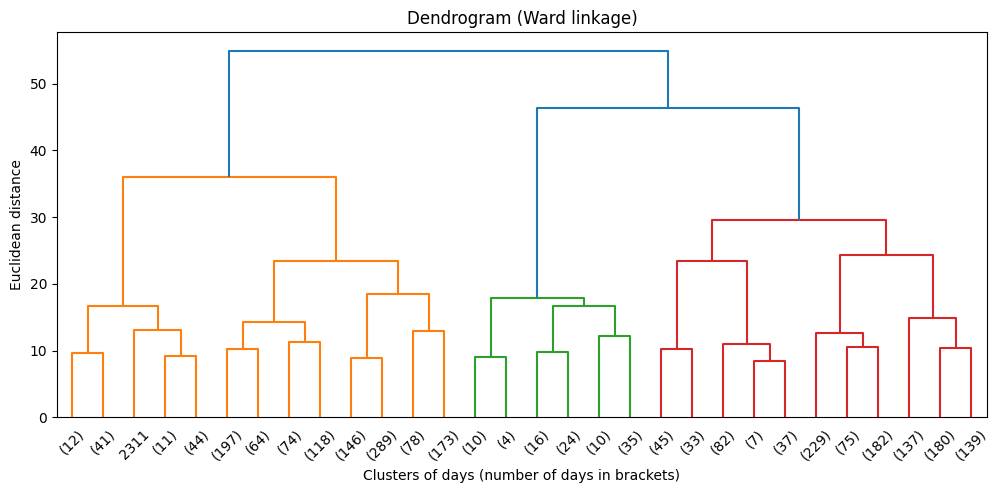

In [67]:
import scipy.cluster.hierarchy as sch

# Dendrogram with Ward linkage (last 30 merges only), as in Tutorial 2
plt.figure(figsize=(12, 5))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'), truncate_mode='lastp', p=30)
plt.title('Dendrogram (Ward linkage)')
plt.xlabel('Clusters of days (number of days in brackets)')
plt.ylabel('Euclidean distance')
plt.show()

> I fit the Agglomerative model with 3 clusters and Ward linkage, because the dendrogram’s largest gap gives 3 clusters. I save the cluster of each day and describe each cluster with the average values of the features, in the same way as for K-Means, so I can compare the two algorithms.

In [68]:
from sklearn.cluster import AgglomerativeClustering


agglo = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
cluster_data['Agglo_Cluster'] = agglo.fit_predict(X_scaled)

agglo_profile = cluster_data.groupby('Agglo_Cluster')[cluster_features].mean().round(4)
agglo_profile['Days'] = cluster_data['Agglo_Cluster'].value_counts().sort_index()
agglo_profile

,Log_Return,Volatility_20d,Return_20d,Days
Agglo_Cluster,,,,
0,-0.0047,0.0090,-0.0158,1248
1,0.0055,0.0094,0.0396,1146
2,0.0078,0.0239,-0.0174,99


> As we seen in the course says the linkage method changes the clusters, so I compare Ward with complete, single and average linkage. For each one I calculate the silhouette score, the Davies–Bouldin index and the size of the smallest cluster, because a cluster with only a few days is not a useful market condition.

In [69]:
# Compare linkage methods with k = 3
for link in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)
    smallest = pd.Series(labels).value_counts().min()
    print(f'{link:<9} silhouette = {sil:.3f}   Davies-Bouldin = {dbi:.3f}   smallest cluster = {smallest} days')

ward      silhouette = 0.246   Davies-Bouldin = 1.278   smallest cluster = 99 days
complete  silhouette = 0.505   Davies-Bouldin = 0.795   smallest cluster = 25 days
average   silhouette = 0.682   Davies-Bouldin = 0.466   smallest cluster = 1 days
single    silhouette = 0.690   Davies-Bouldin = 0.281   smallest cluster = 1 days
